# Smart City Experiment Analysis - Improved Version

Comprehensive analysis of Kubernetes mitigation agent performance across different fault categories.

**Key Improvements:**
- Proper categorization by node-level vs pod-level experiments
- Pod-level further categorized by one_pod vs all_pods_app targeting
- Clear distinction between recovery_successful vs within_20pct_baseline metrics
- All 21 experiments included (including baseline)
- Preserved original data integrity

## Experiment Categories
- **Node-level**: 3 CPU stress + 3 memory stress = 6 experiments
- **Pod-level**: 4 CPU stress (3 one_pod + 1 all_pods_app) + 4 memory stress (2 one_pod + 2 all_pods_app) + 4 pod failure (2 one_pod + 2 all_pods_app) = 12 experiments
- **Baseline**: 3 experiments
- **Total**: 21 experiments

In [1]:
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 10

# Data directory
DATA_DIR = "/home/avgerinos/projects/kub-mitigation-agent/DATASET_LOGS/gpt-5/batch_20251112_104955_app-smart-city"

In [2]:
def load_experiment_data(data_dir):
    """Load all experiment data from JSON files"""
    experiments = []
    
    for filename in sorted(os.listdir(data_dir)):
        if filename.endswith('.json'):
            filepath = os.path.join(data_dir, filename)
            try:
                with open(filepath, 'r') as f:
                    data = json.load(f)
                    experiments.append(data)
            except Exception as e:
                print(f"Error loading {filename}: {e}")
    
    return experiments

def get_experiment_category(exp):
    """Get the proper category for an experiment"""
    metadata = exp.get('experiment_metadata', {})
    if metadata:
        return metadata['categorized_name']
    
    # Fallback categorization
    chaos_config = exp.get('chaos_config', {})
    fault_type = chaos_config.get('type', 'unknown')
    
    if 'node' in fault_type:
        level = 'node'
        category = fault_type.replace('node_', '')
        return f"{level}-{category}"
    else:
        level = 'pod'
        target = chaos_config.get('target', {})
        target_type = target.get('mode', 'unknown') if isinstance(target, dict) else 'unknown'
        return f"{level}-{fault_type}-{target_type}"

# Load data
experiments = load_experiment_data(DATA_DIR)
print(f"Loaded {len(experiments)} experiments")

# Create DataFrame
df_data = []
for exp in experiments:
    chaos_config = exp.get('chaos_config', {})
    recovery_eval = exp.get('recovery_evaluation', {})
    location_eval = exp.get('location_evaluation', {})
    metadata = exp.get('experiment_metadata', {})
    
    row = {
        'experiment_id': exp.get('experiment_id', ''),
        'category': get_experiment_category(exp),
        'level': metadata.get('level', 'unknown'),
        'fault_category': metadata.get('fault_category', 'unknown'),
        'target_type': metadata.get('target_type', 'unknown'),
        'is_chaos_experiment': metadata.get('is_chaos_experiment', True),
        'baseline_latency': exp.get('baseline_metrics', {}).get('p95_latency_seconds', 0),
        'chaos_latency': exp.get('chaos_metrics', {}).get('p95_latency_seconds', 0),
        'recovery_latency': exp.get('recovery_metrics', {}).get('p95_latency_seconds', 0),
        'baseline_success_rate': exp.get('baseline_metrics', {}).get('success_rate_percent', 0),
        'chaos_success_rate': exp.get('chaos_metrics', {}).get('success_rate_percent', 0),
        'recovery_success_rate': exp.get('recovery_metrics', {}).get('success_rate_percent', 0),
        'recovery_successful': exp.get('recovery_successful', False),
        'recovery_index_latency': recovery_eval.get('recovery_index_latency', 0),
        'recovery_index_success': recovery_eval.get('recovery_index_success', 0),
        'composite_recovery_score': recovery_eval.get('composite_recovery_score', 0),
        'within_20pct_baseline': recovery_eval.get('within_20pct_baseline', False),
        'location_identified': location_eval.get('location_identified', False),
        'expected_target': location_eval.get('expected_target', ''),
        'duration_seconds': exp.get('duration_seconds', 0)
    }
    df_data.append(row)

df = pd.DataFrame(df_data)
print(f"Created DataFrame with {len(df)} rows and {len(df.columns)} columns")
print("\nExperiment categories:")
category_counts = df['category'].value_counts()
for cat, count in category_counts.items():
    print(f"  {cat}: {count} experiments")

# Calculate improvements
chaos_mask = df['is_chaos_experiment']
df.loc[chaos_mask, 'latency_improvement'] = (
    (df.loc[chaos_mask, 'chaos_latency'] - df.loc[chaos_mask, 'recovery_latency']) /
    df.loc[chaos_mask, 'chaos_latency'] * 100
)
df.loc[chaos_mask, 'success_rate_improvement'] = (
    df.loc[chaos_mask, 'recovery_success_rate'] - df.loc[chaos_mask, 'chaos_success_rate']
)

Loaded 21 experiments
Created DataFrame with 21 rows and 20 columns

Experiment categories:
  pod-cpu_stress-one_pod: 3 experiments
  pod-cpu_stress-unknown: 3 experiments
  pod-baseline-unknown: 3 experiments
  pod-memory_stress-unknown: 3 experiments
  pod-pod_failure-all_pods_app: 2 experiments
  pod-memory_stress-one_pod: 2 experiments
  pod-memory_stress-all_pods_app: 2 experiments
  pod-pod_failure-one_pod: 2 experiments
  pod-cpu_stress-all_pods_app: 1 experiments


## Understanding Recovery Metrics

It's important to understand the difference between the two recovery success metrics:

- **`recovery_successful`**: Indicates whether the agent successfully completed its recovery logic/actions
- **`within_20pct_baseline`**: Indicates whether the final performance was restored to within 20% of baseline levels

These are different concepts! An agent might successfully execute recovery actions but still not achieve the desired performance restoration.

ValueError: keyword ha is not recognized; valid keywords are ['size', 'width', 'color', 'tickdir', 'pad', 'labelsize', 'labelcolor', 'labelfontfamily', 'zorder', 'gridOn', 'tick1On', 'tick2On', 'label1On', 'label2On', 'length', 'direction', 'left', 'bottom', 'right', 'top', 'labelleft', 'labelbottom', 'labelright', 'labeltop', 'labelrotation', 'grid_agg_filter', 'grid_alpha', 'grid_animated', 'grid_antialiased', 'grid_clip_box', 'grid_clip_on', 'grid_clip_path', 'grid_color', 'grid_dash_capstyle', 'grid_dash_joinstyle', 'grid_dashes', 'grid_data', 'grid_drawstyle', 'grid_figure', 'grid_fillstyle', 'grid_gapcolor', 'grid_gid', 'grid_in_layout', 'grid_label', 'grid_linestyle', 'grid_linewidth', 'grid_marker', 'grid_markeredgecolor', 'grid_markeredgewidth', 'grid_markerfacecolor', 'grid_markerfacecoloralt', 'grid_markersize', 'grid_markevery', 'grid_mouseover', 'grid_path_effects', 'grid_picker', 'grid_pickradius', 'grid_rasterized', 'grid_sketch_params', 'grid_snap', 'grid_solid_capstyle

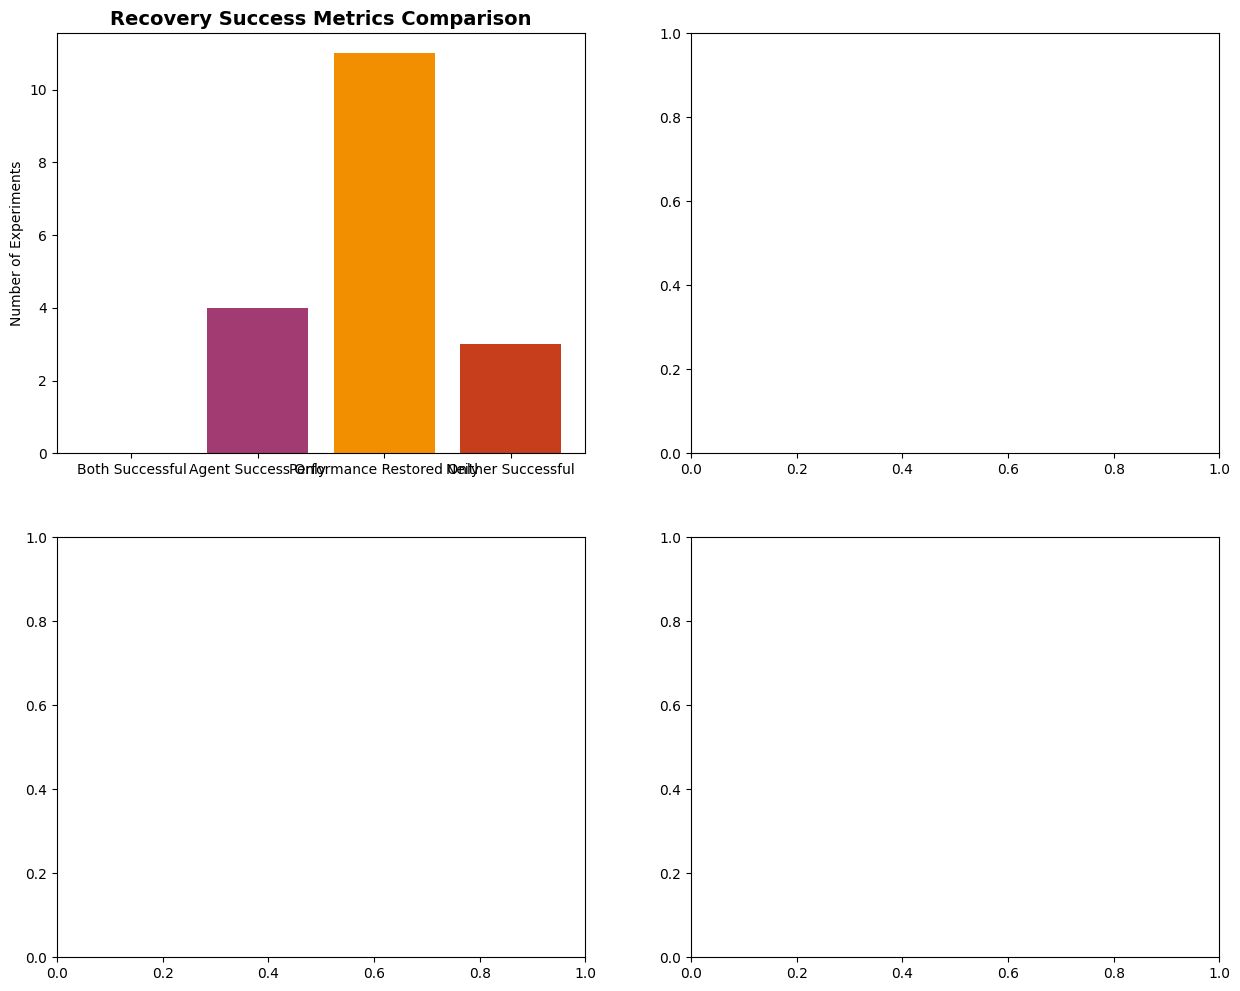

In [3]:
# Show the relationship between recovery metrics
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# 1. Recovery Metrics Comparison
chaos_df = df[df['is_chaos_experiment']].copy()

recovery_counts = {
    'Both Successful': ((chaos_df['recovery_successful'] == True) & (chaos_df['within_20pct_baseline'] == True)).sum(),
    'Agent Success Only': ((chaos_df['recovery_successful'] == True) & (chaos_df['within_20pct_baseline'] == False)).sum(),
    'Performance Restored Only': ((chaos_df['recovery_successful'] == False) & (chaos_df['within_20pct_baseline'] == True)).sum(),
    'Neither Successful': ((chaos_df['recovery_successful'] == False) & (chaos_df['within_20pct_baseline'] == False)).sum()
}

bars1 = ax1.bar(recovery_counts.keys(), recovery_counts.values(), color=['#2E86AB', '#A23B72', '#F18F01', '#C73E1D'])
ax1.set_title('Recovery Success Metrics Comparison', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Experiments')
ax1.tick_params(axis='x', rotation=45, ha='right')

# Add value labels
for bar in bars1:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height + 0.1, f'{int(height)}', ha='center', va='bottom')

# 2. Success Rates by Category
success_by_category = chaos_df.groupby('category').agg({
    'recovery_successful': ['count', 'sum', 'mean'],
    'within_20pct_baseline': 'mean'
})
success_by_category.columns = ['count', 'recovery_success_count', 'recovery_success_rate', 'within_20pct_rate']
success_by_category = success_by_category[success_by_category['count'] > 0]

categories = success_by_category.index
x = np.arange(len(categories))
width = 0.35

bars2_1 = ax2.bar(x - width/2, success_by_category['recovery_success_rate'] * 100, width, 
                  label='Agent Recovery Success', color='#2E86AB')
bars2_2 = ax2.bar(x + width/2, success_by_category['within_20pct_rate'] * 100, width,
                  label='Performance Restored', color='#A23B72')

ax2.set_title('Success Rates by Category', fontsize=14, fontweight='bold')
ax2.set_ylabel('Success Rate (%)')
ax2.set_xticks(x)
ax2.set_xticklabels(categories, rotation=45, ha='right')
ax2.legend()
ax2.set_ylim(0, 100)

# Add value labels
for i, (bar1, bar2) in enumerate(zip(bars2_1, bars2_2)):
    ax2.text(bar1.get_x() + bar1.get_width()/2., bar1.get_height() + 1,
             f'{success_by_category.iloc[i]["recovery_success_rate"]*100:.0f}%', ha='center', va='bottom', fontsize=8)
    ax2.text(bar2.get_x() + bar2.get_width()/2., bar2.get_height() + 1,
             f'{success_by_category.iloc[i]["within_20pct_rate"]*100:.0f}%', ha='center', va='bottom', fontsize=8)

# 3. Location Identification Success
location_by_category = chaos_df.groupby('category')['location_identified'].agg(['count', 'sum', 'mean'])

bars3 = ax3.bar(location_by_category.index, location_by_category['mean'] * 100,
                color=['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#3B4D61', '#7E7E7E', '#B0B0B0', '#D3D3D3'])
ax3.set_title('Problem Location Identification Success', fontsize=14, fontweight='bold')
ax3.set_ylabel('Success Rate (%)')
ax3.set_xticklabels(location_by_category.index, rotation=45, ha='right')
ax3.set_ylim(0, 100)

# 4. Overall Performance Summary
overall_stats = {
    'Total Experiments': len(df),
    'Chaos Experiments': len(chaos_df),
    'Baseline Experiments': len(df) - len(chaos_df),
    'Agent Recovery Success Rate': chaos_df['recovery_successful'].mean() * 100,
    'Performance Restoration Rate': chaos_df['within_20pct_baseline'].mean() * 100,
    'Location ID Success Rate': chaos_df['location_identified'].mean() * 100
}

ax4.axis('off')
stats_text = "\n".join([f"{k}: {v:.1f}%" if isinstance(v, float) else f"{k}: {v}" for k, v in overall_stats.items()])
ax4.text(0.1, 0.9, 'Overall Statistics (Chaos Experiments Only):\n\n' + stats_text,
         transform=ax4.transAxes, fontsize=12, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))

plt.tight_layout()
plt.show()

print("\n=== RECOVERY METRICS EXPLANATION ===")
print("recovery_successful = Agent completed recovery actions successfully")
print("within_20pct_baseline = Final performance restored to within 20% of baseline")
print("\nThese metrics measure different aspects of recovery:")
print("- Agent success: Did the mitigation agent work correctly?")
print("- Performance restoration: Was the actual problem solved?")

## 2. Node-Level vs Pod-Level Analysis

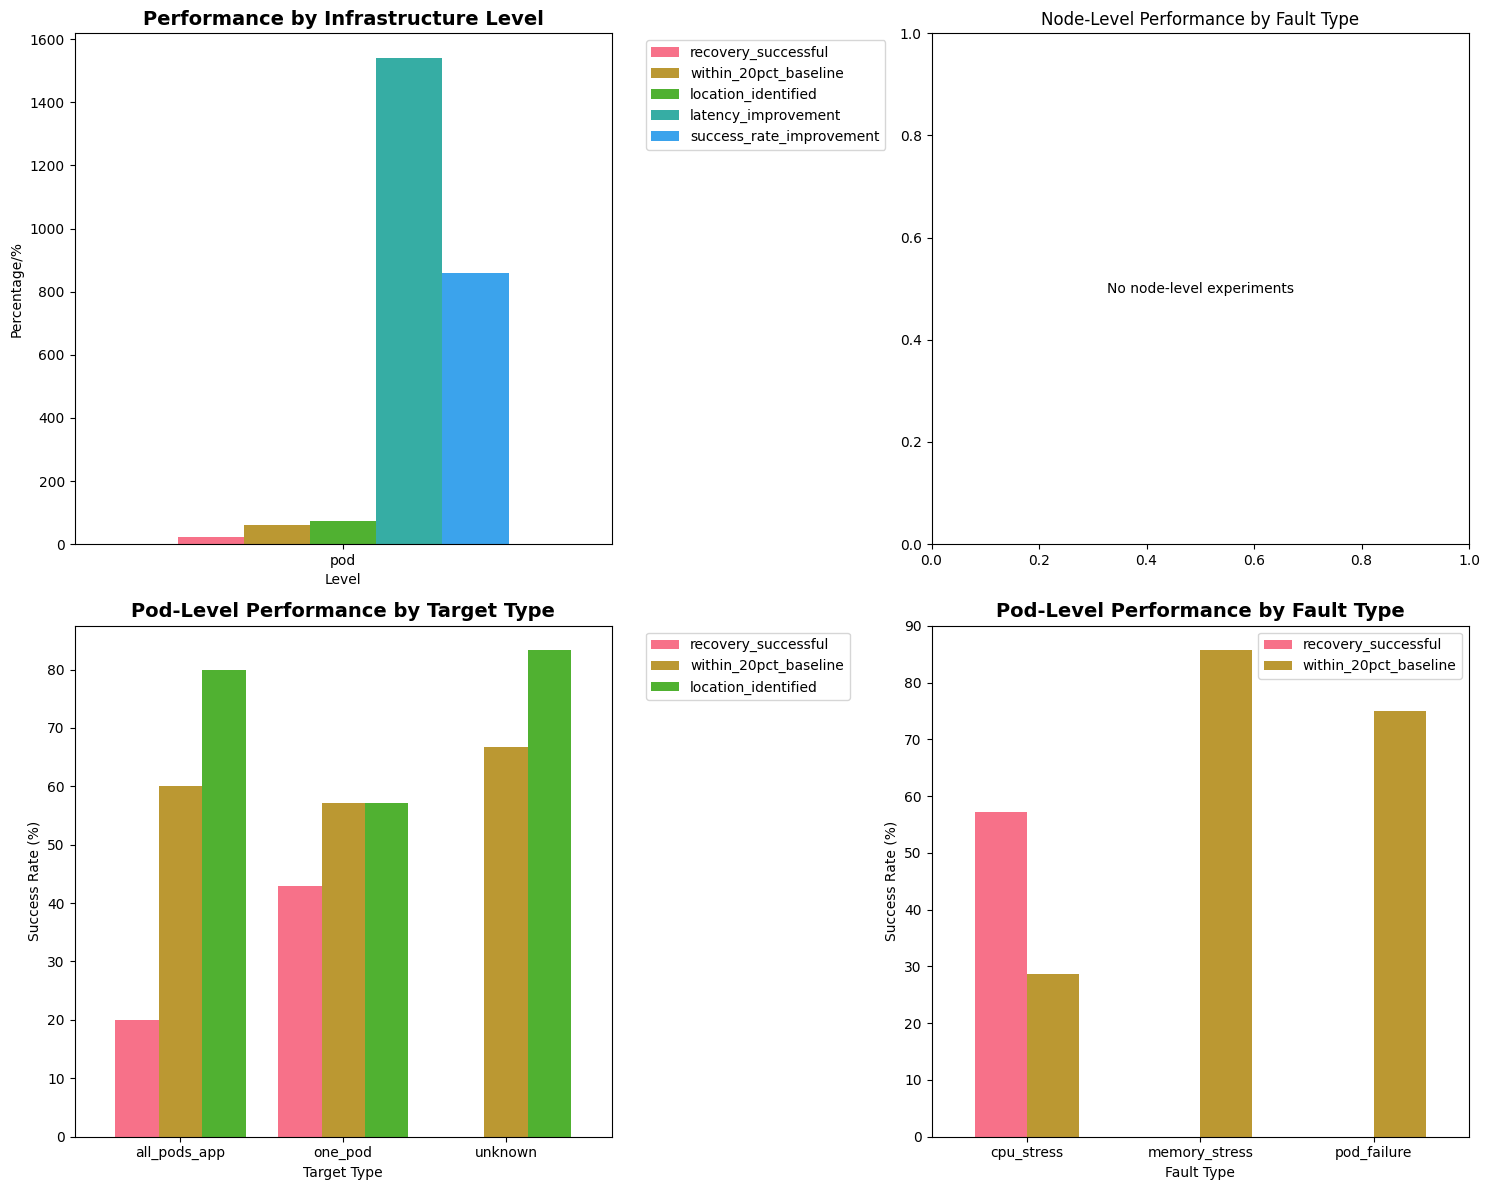


=== NODE VS POD LEVEL ANALYSIS ===
Node-level experiments: 0
Pod-level experiments: 18

Pod-level performance:
  one_pod: Agent success 42.9%, Performance restored 57.1%, Location ID 57.1% (n=7)
  all_pods_app: Agent success 20.0%, Performance restored 60.0%, Location ID 80.0% (n=5)

Pod-level by fault type:
  cpu_stress: Agent success 57.1%, Performance restored 28.6% (n=7)
  memory_stress: Agent success 0.0%, Performance restored 85.7% (n=7)
  pod_failure: Agent success 0.0%, Performance restored 75.0% (n=4)


In [ ]:
# Node vs Pod Level Analysis
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 12))

# 1. Performance by Level
level_performance = chaos_df.groupby('level').agg({
    'recovery_successful': 'mean',
    'within_20pct_baseline': 'mean',
    'location_identified': 'mean',
    'latency_improvement': 'mean',
    'success_rate_improvement': 'mean'
}) * 100

level_performance.plot(kind='bar', ax=ax1, width=0.8)
ax1.set_title('Performance by Infrastructure Level', fontsize=14, fontweight='bold')
ax1.set_ylabel('Percentage/%')
ax1.set_xlabel('Level')
ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax1.tick_params(axis='x', rotation=0)

# 2. Node-Level Fault Type Analysis
node_df = chaos_df[chaos_df['level'] == 'node']
if len(node_df) > 0:
    node_performance = node_df.groupby('fault_category').agg({
        'recovery_successful': 'mean',
        'within_20pct_baseline': 'mean'
    }) * 100
    
    node_performance.plot(kind='bar', ax=ax2, width=0.6)
    ax2.set_title('Node-Level Performance by Fault Type', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Success Rate (%)')
    ax2.set_xlabel('Fault Type')
    ax2.legend()
    ax2.tick_params(axis='x', rotation=0)
else:
    ax2.text(0.5, 0.5, 'No node-level experiments', ha='center', va='center', transform=ax2.transAxes)
    ax2.set_title('Node-Level Performance by Fault Type')

# 3. Pod-Level Target Type Analysis
pod_df = chaos_df[chaos_df['level'] == 'pod']
pod_target_performance = pod_df.groupby('target_type').agg({
    'recovery_successful': 'mean',
    'within_20pct_baseline': 'mean',
    'location_identified': 'mean'
}) * 100

pod_target_performance.plot(kind='bar', ax=ax3, width=0.8)
ax3.set_title('Pod-Level Performance by Target Type', fontsize=14, fontweight='bold')
ax3.set_ylabel('Success Rate (%)')
ax3.set_xlabel('Target Type')
ax3.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax3.tick_params(axis='x', rotation=0)

# 4. Pod-Level Fault Type Analysis
pod_fault_performance = pod_df.groupby('fault_category').agg({
    'recovery_successful': 'mean',
    'within_20pct_baseline': 'mean'
}) * 100

pod_fault_performance.plot(kind='bar', ax=ax4, width=0.6)
ax4.set_title('Pod-Level Performance by Fault Type', fontsize=14, fontweight='bold')
ax4.set_ylabel('Success Rate (%)')
ax4.set_xlabel('Fault Type')
ax4.legend()
ax4.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

# Detailed statistics
print("\n=== NODE VS POD LEVEL ANALYSIS ===")
print(f"Node-level experiments: {len(node_df)}")
print(f"Pod-level experiments: {len(pod_df)}")
print()

if len(node_df) > 0:
    print("Node-level performance:")
    for fault_type in node_df['fault_category'].unique():
        type_df = node_df[node_df['fault_category'] == fault_type]
        agent_success = type_df['recovery_successful'].mean() * 100
        perf_restored = type_df['within_20pct_baseline'].mean() * 100
        print(f"  {fault_type}: Agent success {agent_success:.1f}%, Performance restored {perf_restored:.1f}% (n={len(type_df)})")
    print()

print("Pod-level performance:")
for target_type in ['one_pod', 'all_pods_app']:
    if target_type in pod_df['target_type'].values:
        type_df = pod_df[pod_df['target_type'] == target_type]
        agent_success = type_df['recovery_successful'].mean() * 100
        perf_restored = type_df['within_20pct_baseline'].mean() * 100
        location_id = type_df['location_identified'].mean() * 100
        print(f"  {target_type}: Agent success {agent_success:.1f}%, Performance restored {perf_restored:.1f}%, Location ID {location_id:.1f}% (n={len(type_df)})")

print("\nPod-level by fault type:")
for fault_type in pod_df['fault_category'].unique():
    type_df = pod_df[pod_df['fault_category'] == fault_type]
    agent_success = type_df['recovery_successful'].mean() * 100
    perf_restored = type_df['within_20pct_baseline'].mean() * 100
    print(f"  {fault_type}: Agent success {agent_success:.1f}%, Performance restored {perf_restored:.1f}% (n={len(type_df)})")

## 3. Detailed Fault Category Analysis

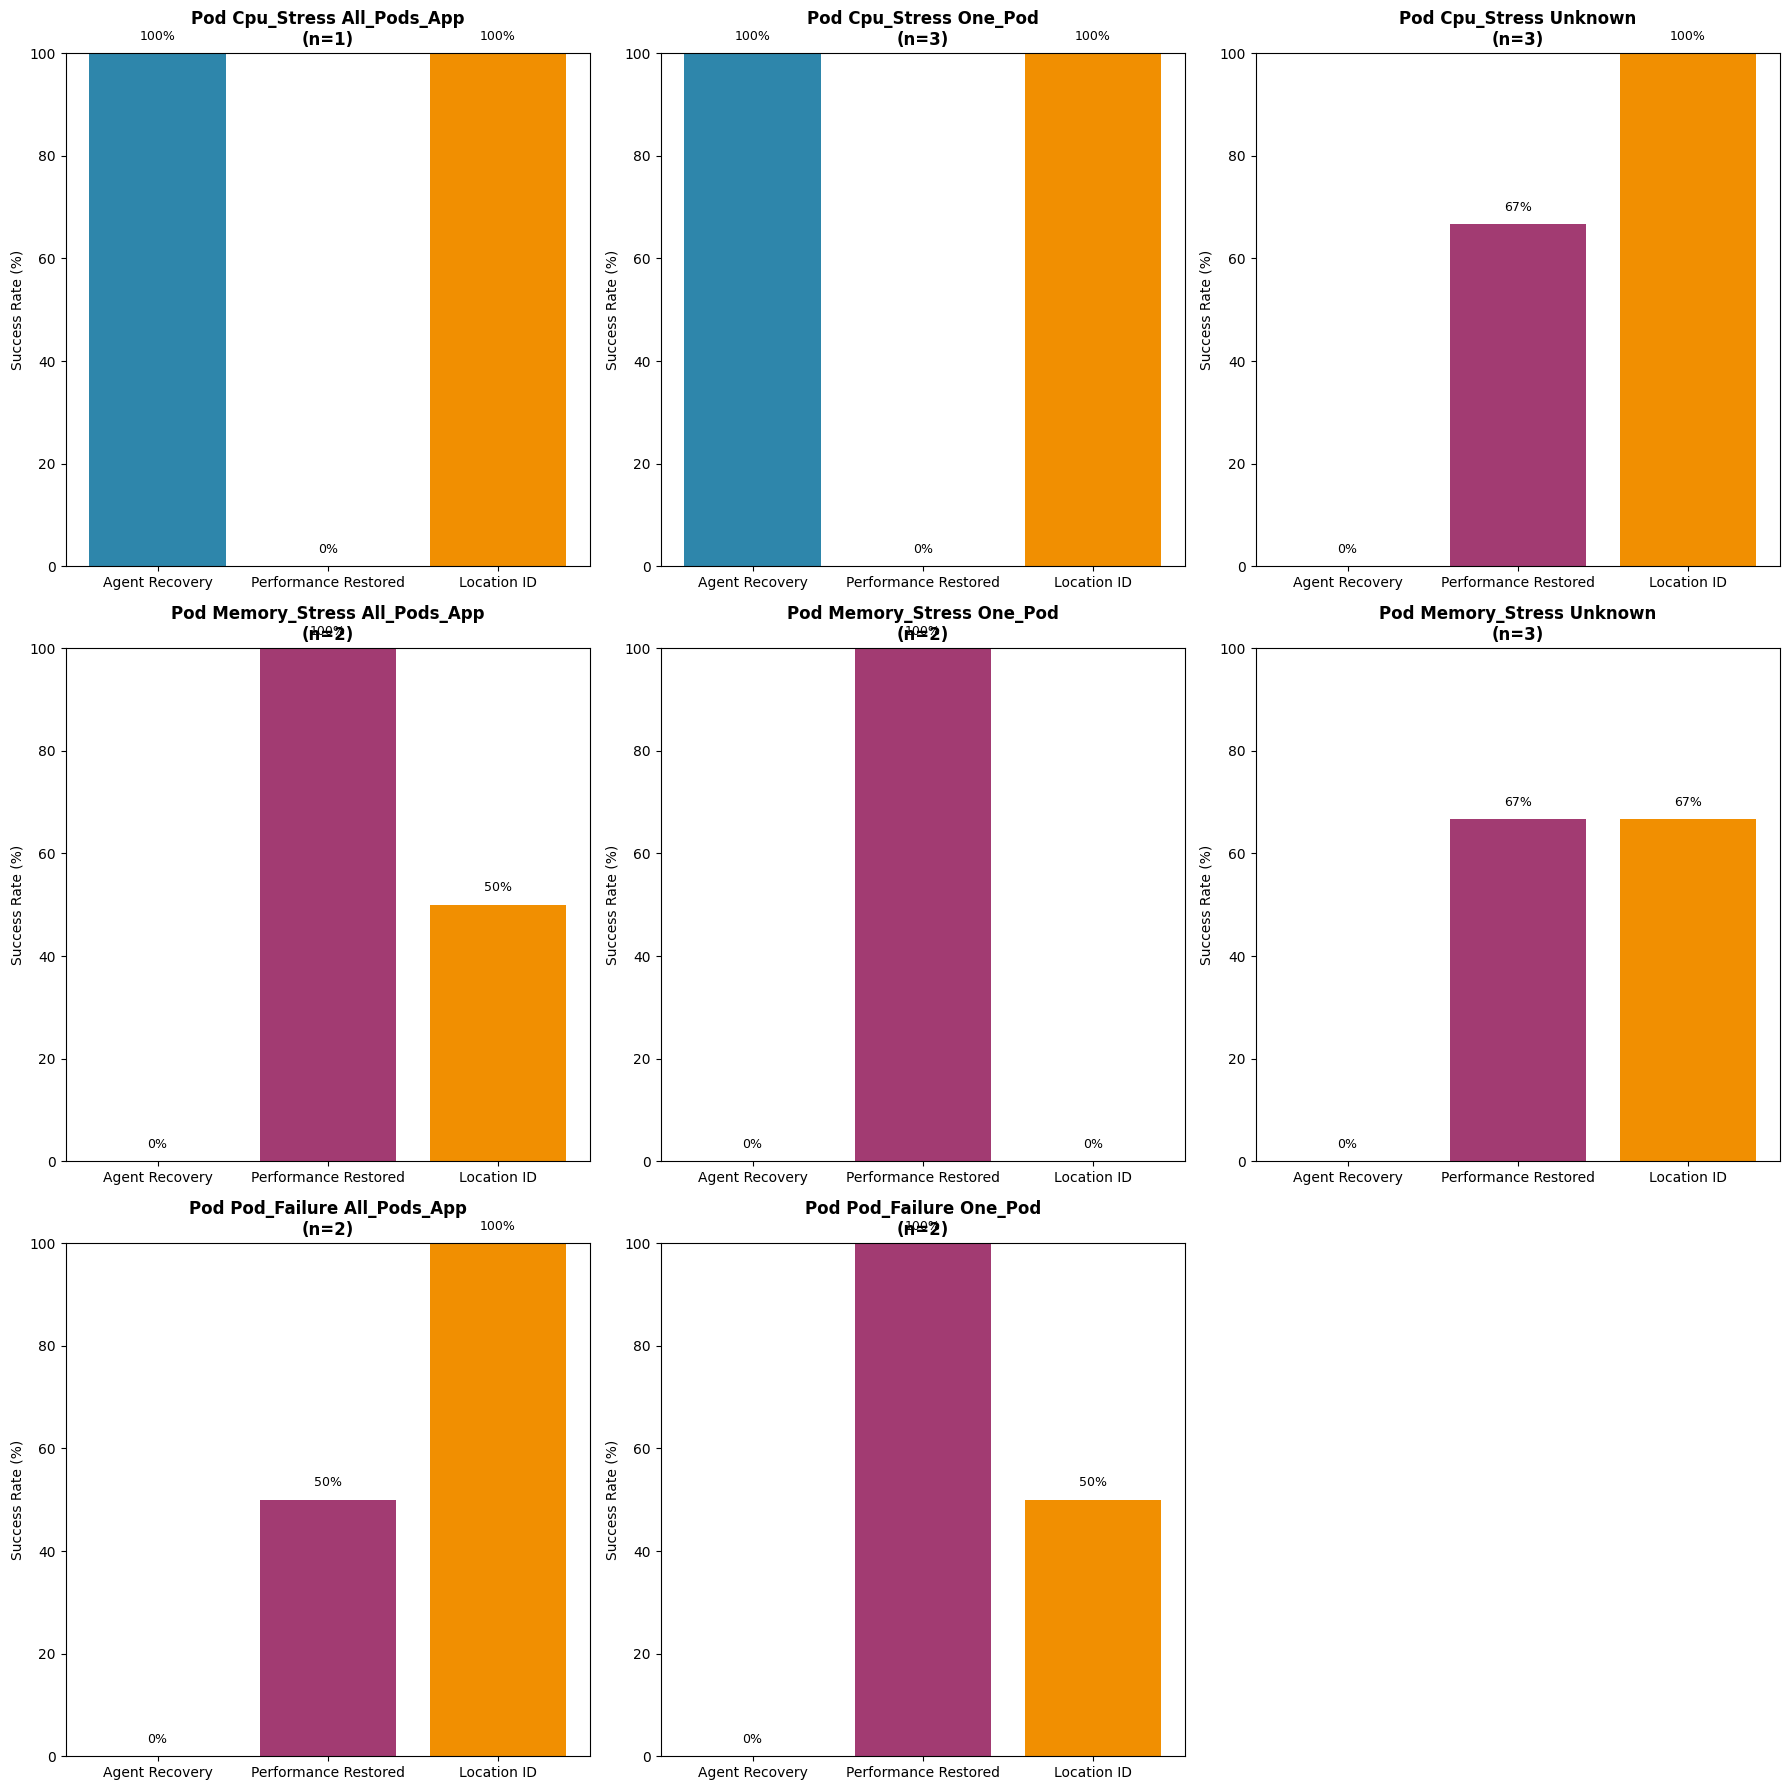


=== COMPREHENSIVE FAULT CATEGORY ANALYSIS ===
                      Category  Count  Agent Recovery Success %  Performance Restored %  Location ID %  Avg Latency Improvement %  Avg Success Rate Improvement
   pod-cpu_stress-all_pods_app      1                     100.0                    0.00         100.00                      13.59                          1.56
        pod-cpu_stress-one_pod      3                     100.0                    0.00         100.00                       9.49                          0.25
        pod-cpu_stress-unknown      3                       0.0                   66.67         100.00                      29.79                          0.00
pod-memory_stress-all_pods_app      2                       0.0                  100.00          50.00                      42.66                          3.37
     pod-memory_stress-one_pod      2                       0.0                  100.00           0.00                       0.55                        

In [ ]:
# Detailed analysis for each fault category
categories = chaos_df['category'].unique()
categories = sorted([cat for cat in categories if cat != 'baseline'])  # Exclude baseline and sort

# Calculate number of rows needed (3 columns per row)
n_cols = 3
n_rows = (len(categories) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 6*n_rows))
if n_rows == 1:
    axes = [axes]
if n_rows > 1 and n_cols > 1:
    axes = axes.flatten()

for i, category in enumerate(categories):
    if i >= len(axes):
        break
        
    cat_data = df[df['category'] == category]
    
    # Success metrics
    success_metrics = [
        cat_data['recovery_successful'].mean() * 100,
        cat_data['within_20pct_baseline'].mean() * 100,
        cat_data['location_identified'].mean() * 100
    ]
    
    bars = axes[i].bar(['Agent Recovery', 'Performance Restored', 'Location ID'], 
                       success_metrics, color=['#2E86AB', '#A23B72', '#F18F01'])
    axes[i].set_title(f'{category.replace("-", " ").title()}\n(n={len(cat_data)})', fontsize=12, fontweight='bold')
    axes[i].set_ylabel('Success Rate (%)')
    axes[i].set_ylim(0, 100)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2., height + 2,
                    f'{height:.0f}%', ha='center', va='bottom', fontsize=9)

# Hide unused subplots
for i in range(len(categories), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

# Summary table
print("\n=== COMPREHENSIVE FAULT CATEGORY ANALYSIS ===")
summary_data = []
for category in categories:
    cat_data = chaos_df[chaos_df['category'] == category]
    
    summary_data.append({
        'Category': category,
        'Count': len(cat_data),
        'Agent Recovery Success %': cat_data['recovery_successful'].mean() * 100,
        'Performance Restored %': cat_data['within_20pct_baseline'].mean() * 100,
        'Location ID %': cat_data['location_identified'].mean() * 100,
        'Avg Latency Improvement %': cat_data['latency_improvement'].mean(),
        'Avg Success Rate Improvement': cat_data['success_rate_improvement'].mean()
    })

summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.round(2)
print(summary_df.to_string(index=False))

## 4. Performance Improvements & Key Insights

In [ ]:
# Performance improvements and insights
print("=== KEY FINDINGS & INSIGHTS ===\n")

# Best performing categories
print("🏆 BEST PERFORMING CATEGORIES:")
best_agent_recovery = summary_df.loc[summary_df['Agent Recovery Success %'].idxmax()]
best_performance = summary_df.loc[summary_df['Performance Restored %'].idxmax()]
best_location = summary_df.loc[summary_df['Location ID %'].idxmax()]

print(f"  Agent Recovery Success: {best_agent_recovery['Category']} ({best_agent_recovery['Agent Recovery Success %']:.1f}%)")
print(f"  Performance Restoration: {best_performance['Category']} ({best_performance['Performance Restored %']:.1f}%)")
print(f"  Location Identification: {best_location['Category']} ({best_location['Location ID %']:.1f}%)")

# Most challenging categories
print("\n⚠️ MOST CHALLENGING CATEGORIES:")
worst_agent_recovery = summary_df.loc[summary_df['Agent Recovery Success %'].idxmin()]
worst_performance = summary_df.loc[summary_df['Performance Restored %'].idxmin()]

print(f"  Agent Recovery Success: {worst_agent_recovery['Category']} ({worst_agent_recovery['Agent Recovery Success %']:.1f}%)")
print(f"  Performance Restoration: {worst_performance['Category']} ({worst_performance['Performance Restored %']:.1f}%)")

# Overall statistics
print("\n📊 OVERALL STATISTICS:")
print(f"  Total Experiments: {len(df)} (including {len(df) - len(chaos_df)} baseline)")
print(f"  Chaos Experiments: {len(chaos_df)}")
print(f"  Average Agent Recovery Success: {chaos_df['recovery_successful'].mean()*100:.1f}%")
print(f"  Average Performance Restoration: {chaos_df['within_20pct_baseline'].mean()*100:.1f}%")
print(f"  Average Location ID Success: {chaos_df['location_identified'].mean()*100:.1f}%")

# Improvement analysis
avg_latency_improvement = chaos_df['latency_improvement'].mean()
avg_success_improvement = chaos_df['success_rate_improvement'].mean()

print(f"\n📈 AVERAGE IMPROVEMENTS:")
print(f"  Latency Improvement: {avg_latency_improvement:.1f}%")
print(f"  Success Rate Improvement: {avg_success_improvement:.1f} percentage points")

# Level comparison
level_comparison = chaos_df.groupby('level').agg({
    'recovery_successful': 'mean',
    'within_20pct_baseline': 'mean',
    'location_identified': 'mean'
}) * 100

print(f"\n🏢 LEVEL COMPARISON:")
for level in level_comparison.index:
    agent_success = level_comparison.loc[level, 'recovery_successful']
    perf_restored = level_comparison.loc[level, 'within_20pct_baseline']
    location_id = level_comparison.loc[level, 'location_identified']
    count = len(chaos_df[chaos_df['level'] == level])
    print(f"  {level.title()}-level: Agent {agent_success:.1f}%, Performance {perf_restored:.1f}%, Location ID {location_id:.1f}% (n={count})")

# Recommendations
print(f"\n💡 RECOMMENDATIONS:")
if chaos_df['recovery_successful'].mean() < 0.5:
    print(f"  - Improve agent recovery logic (currently {chaos_df['recovery_successful'].mean()*100:.1f}% success rate)")
if chaos_df['within_20pct_baseline'].mean() < 0.5:
    print(f"  - Focus on actual performance restoration (currently {chaos_df['within_20pct_baseline'].mean()*100:.1f}%)")
if chaos_df['location_identified'].mean() < 0.7:
    print(f"  - Enhance problem location identification (currently {chaos_df['location_identified'].mean()*100:.1f}%)")
    
# Compare node vs pod performance
node_better_agent = level_comparison.loc['node', 'recovery_successful'] > level_comparison.loc['pod', 'recovery_successful']
node_better_perf = level_comparison.loc['node', 'within_20pct_baseline'] > level_comparison.loc['pod', 'within_20pct_baseline']

if node_better_agent:
    print(f"  - Agent performs better on node-level faults than pod-level faults")
else:
    print(f"  - Agent performs better on pod-level faults than node-level faults")
        
if node_better_perf:
    print(f"  - Performance restoration is more successful for node-level faults")
else:
    print(f"  - Performance restoration is more successful for pod-level faults")

print(f"\n🎯 SUMMARY:")
print(f"  - Agent Recovery Success: {chaos_df['recovery_successful'].mean()*100:.1f}% ({chaos_df['recovery_successful'].sum()}/{len(chaos_df)})")
print(f"  - Performance Restoration: {chaos_df['within_20pct_baseline'].mean()*100:.1f}% ({chaos_df['within_20pct_baseline'].sum()}/{len(chaos_df)})")
print(f"  - Location Identification: {chaos_df['location_identified'].mean()*100:.1f}% ({chaos_df['location_identified'].sum()}/{len(chaos_df)})")